In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df1 = pd.read_csv('/content/matches.csv')
df1.head()

,match_id,season,venue,team1,team2,toss_winner,toss_decision,winner
0,1001,2024,M. Chinnaswamy Stadium,RCB,GT,RCB,field,GT
1,1002,2025,Narendra Modi Stadium,GT,MI,MI,field,MI
2,1003,2024,MA Chidambaram Stadium,CSK,KKR,CSK,bat,CSK
3,1004,2026,Wankhede Stadium,MI,RCB,MI,field,RCB
4,1005,2025,Eden Gardens,KKR,CSK,CSK,field,KKR


In [3]:
df2 = pd.read_csv('/content/deliveries.csv')
df2.head()

,match_id,over,ball,batsman,bowler,batsman_runs,extra_runs,total_runs,dismissal_kind,player_dismissed
0,1001,15,1,Virat Kohli,Jasprit Bumrah,1,0,1,NaN,NaN
1,1001,15,2,MS Dhoni,Jasprit Bumrah,0,0,0,NaN,NaN
2,1001,15,3,Ruturaj Gaikwad,Jasprit Bumrah,4,0,4,NaN,NaN
3,1001,15,4,Rinku Singh,Jasprit Bumrah,1,1,2,NaN,NaN
4,1001,15,5,Hardik Pandya,Jasprit Bumrah,6,0,6,NaN,NaN


In [ ]:
df1.info()
df1.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   match_id       30 non-null     int64 
 1   season         30 non-null     int64 
 2   venue          30 non-null     object
 3   team1          30 non-null     object
 4   team2          30 non-null     object
 5   toss_winner    30 non-null     object
 6   toss_decision  30 non-null     object
 7   winner         29 non-null     object
dtypes: int64(2), object(6)
memory usage: 2.0+ KB


,0
match_id,0
season,0
venue,0
team1,0
team2,0
toss_winner,0
toss_decision,0
winner,1


In [ ]:
df2.info()
df2.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   match_id          120 non-null    int64 
 1   over              120 non-null    int64 
 2   ball              120 non-null    int64 
 3   batsman           120 non-null    object
 4   bowler            119 non-null    object
 5   batsman_runs      120 non-null    int64 
 6   extra_runs        120 non-null    int64 
 7   total_runs        120 non-null    int64 
 8   dismissal_kind    12 non-null     object
 9   player_dismissed  12 non-null     object
dtypes: int64(6), object(4)
memory usage: 9.5+ KB


,0
match_id,0
over,0
ball,0
batsman,0
bowler,1
batsman_runs,0
extra_runs,0
total_runs,0
dismissal_kind,108
player_dismissed,108


In [4]:

df1['winner']=df1['winner'].fillna('Not Result')

In [5]:
df2['bowler']=df2['bowler'].fillna(df2['bowler'].mode()[0])

In [6]:
df1.isnull().sum()

,0
match_id,0
season,0
venue,0
team1,0
team2,0
toss_winner,0
toss_decision,0
winner,0


In [7]:
df2.isnull().sum()

,0
match_id,0
over,0
ball,0
batsman,0
bowler,0
batsman_runs,0
extra_runs,0
total_runs,0
dismissal_kind,108
player_dismissed,108


In [17]:
#Q2


batting = df2.groupby("batsman").agg(
    Runs=("batsman_runs", "sum"),
    Balls=("ball", "count"),
    Matches=("match_id", "nunique")
)


batting = batting[batting["Matches"] >=4 ]

batting["Strike Rate"] = np.where(
    batting["Balls"] > 0,
    batting["Runs"] / batting["Balls"] * 100,
    0
)
batting['Average'] = batting['Runs'] / batting['Balls']

batting = batting.sort_values("Strike Rate", ascending=False)
batting

,Runs,Balls,Matches,Strike Rate,Average
batsman,,,,,
MS Dhoni,82,24,4,341.666667,3.416667
Heinrich Klaasen,61,20,4,305.000000,3.050000
Rinku Singh,48,22,4,218.181818,2.181818
Ruturaj Gaikwad,38,18,4,211.111111,2.111111
Hardik Pandya,31,17,4,182.352941,1.823529
Virat Kohli,32,19,4,168.421053,1.684211


In [18]:
# Q2
bowling = df2.groupby("bowler").agg(
    Runs=("total_runs", "sum"),
    Balls=("ball", "count"),
    Matches=("match_id", "nunique")
)

bowling = bowling[bowling["Matches"] >=4]

bowling["Overs"] = bowling["Balls"] / 6

bowling["Economy"] = np.where(
    bowling["Overs"] > 0,
    bowling["Runs"] / bowling["Overs"],
    0
)

bowling

,Runs,Balls,Matches,Overs,Economy
bowler,,,,,
Jasprit Bumrah,40,25,4,4.166667,9.600000
Mitchell Starc,71,24,4,4.000000,17.750000
Rashid Khan,54,24,4,4.000000,13.500000
Ravindra Jadeja,57,23,4,3.833333,14.869565
Yuzvendra Chahal,72,24,4,4.000000,18.000000


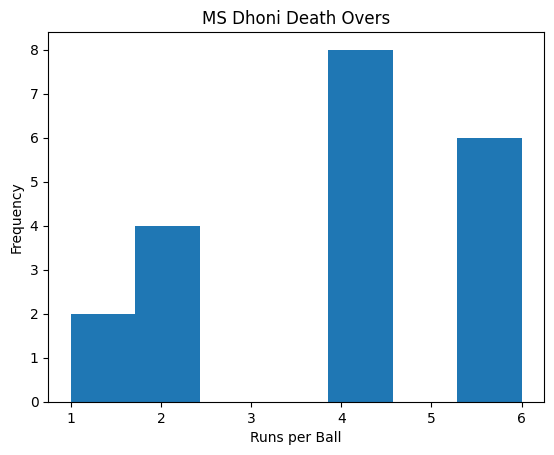

In [8]:


dhoni = df2[
    (df2["batsman"] == "MS Dhoni") &
    (df2["over"] >= 16)
]

plt.hist(dhoni["batsman_runs"], bins=7)
plt.xlabel("Runs per Ball")
plt.ylabel("Frequency")
plt.title("MS Dhoni Death Overs")
plt.show()

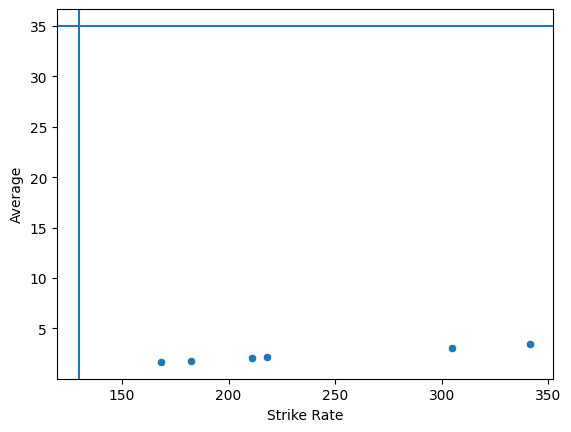

In [11]:
sns.scatterplot(
    data=batting,
    x="Strike Rate",
    y="Average"
)

plt.axvline(130)
plt.axhline(35)

plt.show()

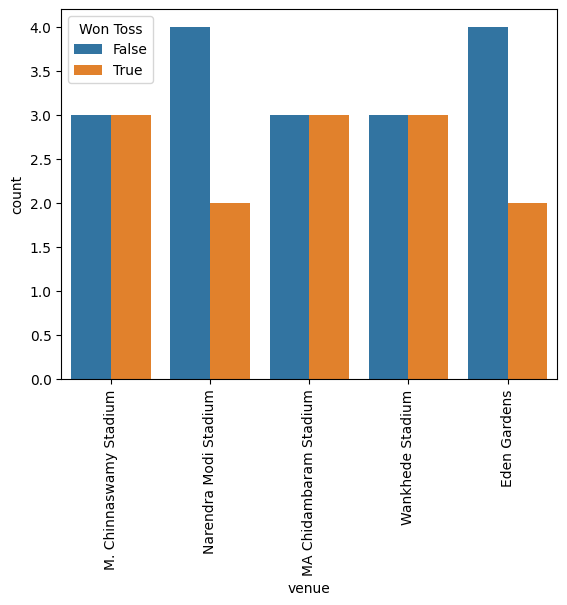

In [12]:


df1["Won Toss"] = df1["toss_winner"] == df1["winner"]

sns.countplot(
    data=df1,
    x="venue",
    hue="Won Toss"
)

plt.xticks(rotation=90)
plt.show()

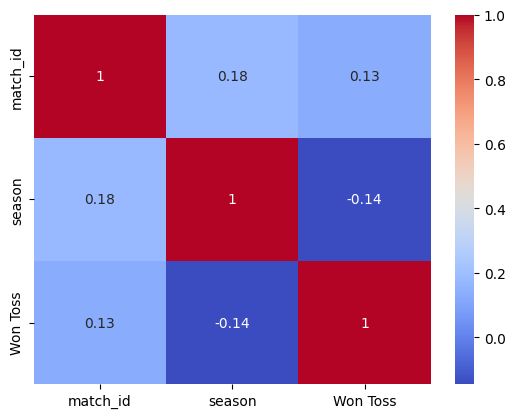

In [13]:
corr = df1.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.show()